# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

## 0. Thiết lập chung

Phần này dùng chung cho cả bốn bài: thư viện, hàm tiện ích, pipeline dữ liệu và
khung huấn luyện/đánh giá theo mục A.1, A.2 và B.7 của tài liệu Lab 2.

In [1]:
# Import thư viện và cố định seed
import copy
import time
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             precision_recall_fscore_support)
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from torchvision.models import resnet18 as tv_resnet18

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch  :", torch.__version__)
print("device :", device)

torch  : 2.11.0+cu130
device : cuda


In [2]:
# Hai hàm tiện ích dùng lại trong cả notebook
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

### Chuẩn bị dữ liệu trên Colab

Lấy file zip từ Google Drive, giải nén vào ổ đĩa của Colab. Ảnh gốc của
VinaFood21 có kích thước lớn, giải nén JPEG mỗi epoch chiếm gần hết thời gian
huấn luyện, nên resize sẵn một lần về cạnh ngắn 256. Pipeline transform của
A.2 giữ nguyên, vẫn `Resize` hoặc `RandomResizedCrop` về đúng `IMG_SIZE` của
từng bài; 256 đủ cho ảnh 224 của Bài 4.

In [3]:
# Mount Google Drive và giải nén VinaFood21 vào /content
from google.colab import drive

drive.mount("/content/drive")
!unzip -q -n "/content/drive/MyDrive/DS/DeepLearning/TH2/VinaFood21.zip" -d /content
!ls /content/VinaFood21

Mounted at /content/drive
README.txt  test  train


In [4]:
# Resize sẵn một lần về cạnh ngắn 256, các epoch sau đọc ảnh nhỏ
from PIL import Image
from torchvision.datasets.folder import IMG_EXTENSIONS

SRC = Path("/content/VinaFood21")
DST = Path("/content/VinaFood21_256")
SHORT_SIDE = 256

n = 0
for path in SRC.rglob("*"):
    if path.suffix.lower() not in IMG_EXTENSIONS:
        continue
    out = DST / path.relative_to(SRC)
    if out.exists():
        continue
    out.parent.mkdir(parents=True, exist_ok=True)

    img = Image.open(path).convert("RGB")
    scale = SHORT_SIDE / min(img.size)
    if scale < 1:
        new_size = (round(img.width * scale), round(img.height * scale))
        img = img.resize(new_size, Image.BILINEAR)
    img.save(out)
    n += 1

print("đã resize", n, "ảnh")

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


đã resize 16726 ảnh


### Pipeline dữ liệu

Bản tải về chỉ có `train/` và `test/`, nên tách 10% của `train/` làm `val/`
bằng `random_split` với seed 42. Cả bốn bài dùng cùng một phép chia.

In [5]:
# Cấu hình chung cho cả bốn bài: đường dẫn, batch size, seed
DATA_ROOT = Path("/content/VinaFood21_256")
BATCH = 32
SEED = 42
VAL_RATIO = 0.1
NUM_WORKERS = 2
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
results = {}                          # kết quả test của mọi mô hình

assert (DATA_ROOT / "train").is_dir(), f"Không thấy {DATA_ROOT.resolve()}"
print("Dữ liệu:", DATA_ROOT.resolve())

Dữ liệu: /content/VinaFood21_256


In [6]:
# Hai bộ transform riêng: train có augment, val/test không
def build_transforms(img_size, augment=True):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    if not augment:
        return eval_tf, eval_tf

    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return train_tf, eval_tf

In [7]:
# Tạo train/val/test DataLoader cho một kích thước ảnh
def build_loaders(img_size, augment=True):
    train_tf, eval_tf = build_transforms(img_size, augment)

    # Hai ImageFolder trỏ cùng thư mục để ảnh val không bị augment
    full_train = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
    full_eval = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
    test_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)
    assert full_train.classes == test_ds.classes

    n_val = int(len(full_train) * VAL_RATIO)
    tr_idx, va_idx = random_split(
        range(len(full_train)), [len(full_train) - n_val, n_val],
        generator=torch.Generator().manual_seed(SEED))
    train_ds = Subset(full_train, list(tr_idx))
    val_ds = Subset(full_eval, list(va_idx))

    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                          num_workers=NUM_WORKERS)
    val_dl = DataLoader(val_ds, batch_size=BATCH, shuffle=False,
                        num_workers=NUM_WORKERS)
    test_dl = DataLoader(test_ds, batch_size=BATCH, shuffle=False,
                         num_workers=NUM_WORKERS)
    return train_dl, val_dl, test_dl

In [8]:
# Kiểm tra số lớp, số ảnh và shape của một batch ở cấu hình 64x64
train_dl, val_dl, test_dl = build_loaders(64)
CLASSES = test_dl.dataset.classes

print("số lớp      :", len(CLASSES))
print("số ảnh train:", len(train_dl.dataset))
print("số ảnh val  :", len(val_dl.dataset))
print("số ảnh test :", len(test_dl.dataset))
print("thứ tự lớp  :", CLASSES[:5], "...")

xb, yb = next(iter(train_dl))
show("một batch vào model", xb)
show("nhãn", yb)

số lớp      : 21
số ảnh train: 9040
số ảnh val  : 1004
số ảnh test : 6682
thứ tự lớp  : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)


### Khung huấn luyện và đánh giá

`train_one_epoch` và `evaluate` giữ nguyên như B.7. `fit` là vòng huấn luyện
của B.7, thêm đo thời gian mỗi epoch và giữ lại trọng số có macro-F1 trên val
cao nhất để đánh giá trên test.

In [9]:
# Huấn luyện một epoch
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                     # bật dropout, BN dùng thống kê batch
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

In [10]:
# Đánh giá, trả về cả y_true và y_pred để tính macro-F1 và confusion matrix
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                      # tắt dropout, BN dùng thống kê tích luỹ
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

In [11]:
# Vòng huấn luyện dùng chung cho cả bốn bài
def fit(model, optimizer, train_dl, val_dl, epochs):
    criterion = nn.CrossEntropyLoss()
    lich_su = []
    best_f1, best_state = -1.0, None
    start = time.time()
    for ep in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion,
                                          optimizer, device)
        va_loss, va_acc, y_true, y_pred = evaluate(model, val_dl, criterion,
                                                   device)
        va_f1 = f1_score(y_true, y_pred, average="macro")
        lich_su.append((ep, tr_loss, va_loss))

        mark = ""
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_state = copy.deepcopy(model.state_dict())
            mark = "  *"
        print(f"epoch {ep:>2}  train {tr_loss:.4f}/{tr_acc:.4f}"
              f"   val {va_loss:.4f}/{va_acc:.4f}  F1 {va_f1:.4f}{mark}")

    sec_per_epoch = (time.time() - start) / epochs
    model.load_state_dict(best_state)
    print(f"\n{sec_per_epoch:.1f} giây/epoch, best val macro-F1 {best_f1:.4f}")
    return lich_su, sec_per_epoch

In [12]:
# Vẽ loss train và val, đánh dấu epoch val loss thấp nhất
def plot_loss(lich_su, title):
    ep, tr, va = zip(*lich_su)
    best_ep = ep[va.index(min(va))]

    plt.figure(figsize=(6, 4))
    plt.plot(ep, tr, label="train loss")
    plt.plot(ep, va, label="val loss")
    plt.axvline(best_ep, color="gray", linestyle="--",
                label=f"val loss thấp nhất (epoch {best_ep})")
    plt.title(title)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()

    if best_ep == ep[-1]:
        print("val loss vẫn giảm đến epoch cuối, chưa thấy đi lên")
    else:
        print("val loss thấp nhất ở epoch", best_ep,
              "rồi đi lên ở các epoch sau")

In [13]:
# Đánh giá trên test: 4 độ đo, F1 từng lớp, confusion matrix 21x21
def report(model, test_dl, name, img_size, sec_per_epoch):
    criterion = nn.CrossEntropyLoss()
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)

    print(f"{'độ đo':<12}{'giá trị':>10}")
    for k, v in [("accuracy", acc), ("precision", prec),
                 ("recall", rec), ("macro-F1", f1)]:
        print(f"{k:<12}{v:>10.4f}")
    print()
    print(classification_report(y_true, y_pred, target_names=CLASSES,
                                digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(11, 9))
    sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")
    plt.title(f"Confusion matrix - {name}")
    plt.xlabel("dự đoán")
    plt.ylabel("nhãn thật")
    plt.show()

    results[name] = dict(img=img_size, params=n_params(model),
                         sec=sec_per_epoch, acc=acc, prec=prec, rec=rec,
                         f1=f1)
    return f1

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

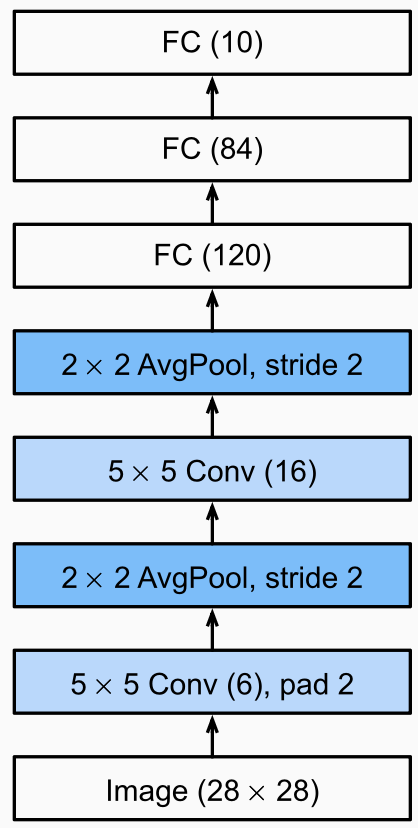

Cấu hình theo B.3: ảnh màu 64x64x3, 21 lớp, C1 không padding, ReLU,
`AvgPool2d(2, 2)`; sau đó thay bằng `MaxPool2d(2, 2)` và chạy lại để so sánh.

In [14]:
# Định nghĩa LeNet-5 với số channel vào, kích thước ảnh và số lớp tham số hoá
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        pool_cls = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = pool_cls(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = pool_cls(2, 2)

        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        # Dò số chiều sau S4 bằng một forward giả, tránh tính tay
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)

In [15]:
# Hàm dựng bảng shape và tham số của từng layer
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0
    for name, layer in [("C1", model.c1), ("S2", model.s2),
                        ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("F5", model.f5), ("F6", model.f6),
                        ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total

In [16]:
# Số tham số và bảng tham số từng layer ở cấu hình 64x64x3, 21 lớp
lenet = LeNet5(in_ch=3, img=64, num_classes=len(CLASSES))
rows, total = layer_table(lenet, 64)

print(f"{'layer':<10}{'output':<16}{'tham số':>12}")
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")

assert lenet.n_flat == 2704
assert total == n_params(lenet) == 339_421

# Nhận xét: tham số dồn gần hết vào F5, hai conv layer rất nhẹ

layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421


In [17]:
# Chạy thử đúng một batch qua LeNet trước khi huấn luyện cả epoch
xb = next(iter(train_dl))[0]
lenet.eval()
with torch.no_grad():
    logits = lenet(xb)

show("input", xb)
show("logits", logits)
assert logits.shape == (xb.shape[0], len(CLASSES))

input                        (32, 3, 64, 64)
logits                       (32, 21)


#### LeNet-5 với AvgPool2d

In [18]:
# Huấn luyện LeNet-5 bản AvgPool, Adam lr 1e-3
EPOCHS_LENET = 20

torch.manual_seed(SEED)
lenet_avg = LeNet5(in_ch=3, img=64, num_classes=len(CLASSES),
                   pool="avg").to(device)
optimizer = torch.optim.Adam(lenet_avg.parameters(), lr=1e-3)
hist_avg, sec_avg = fit(lenet_avg, optimizer, train_dl, val_dl, EPOCHS_LENET)

epoch  1  train 2.7921/0.1596   val 2.6532/0.1982  F1 0.1061  *
epoch  2  train 2.6175/0.1975   val 2.5361/0.2271  F1 0.1712  *
epoch  3  train 2.5056/0.2352   val 2.4586/0.2490  F1 0.1828  *
epoch  4  train 2.4120/0.2559   val 2.4339/0.2550  F1 0.2259  *
epoch  5  train 2.3462/0.2754   val 2.3394/0.2859  F1 0.2491  *
epoch  6  train 2.2823/0.2966   val 2.3149/0.2869  F1 0.2419
epoch  7  train 2.2349/0.3118   val 2.3016/0.2988  F1 0.2597  *
epoch  8  train 2.1922/0.3267   val 2.2911/0.2849  F1 0.2591
epoch  9  train 2.1559/0.3405   val 2.2976/0.2988  F1 0.2800  *
epoch 10  train 2.1126/0.3462   val 2.1942/0.3247  F1 0.2898  *
epoch 11  train 2.0868/0.3518   val 2.2146/0.3267  F1 0.2971  *
epoch 12  train 2.0468/0.3722   val 2.1680/0.3486  F1 0.3258  *
epoch 13  train 2.0227/0.3764   val 2.1939/0.3416  F1 0.3179
epoch 14  train 2.0031/0.3873   val 2.1885/0.3496  F1 0.3212
epoch 15  train 1.9838/0.3918   val 2.1903/0.3317  F1 0.2867
epoch 16  train 1.9546/0.3963   val 2.1664/0.3516  F1 0

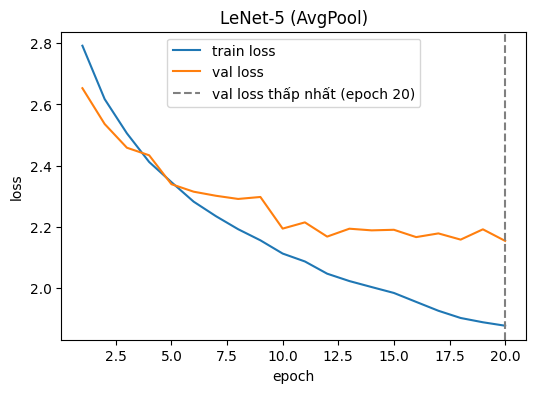

val loss vẫn giảm đến epoch cuối, chưa thấy đi lên
độ đo          giá trị
accuracy        0.3086
precision       0.3061
recall          0.2916
macro-F1        0.2905

                  precision    recall  f1-score   support

        banh-can     0.1677    0.2241    0.1918       241
        banh-hoi     0.3110    0.5272    0.3912       607
    banh-mi-chao     0.2834    0.3668    0.3198       289
        banh-tet     0.1810    0.2088    0.1939       364
 banh-trang-tron     0.2270    0.1197    0.1568       309
          banh-u     0.1965    0.1932    0.1948       176
        banh-uot     0.3427    0.2607    0.2961       560
       bap-nuong     0.1783    0.1608    0.1691       143
          bo-kho     0.3587    0.2929    0.3225       338
       bo-la-lot     0.4539    0.5371    0.4920       458
       bot-chien     0.2434    0.1667    0.1978       276
           ca-ri     0.2074    0.1637    0.1830       171
    canh-kho-qua     0.3578    0.5552    0.4351       290
   canh-khoai-mo    

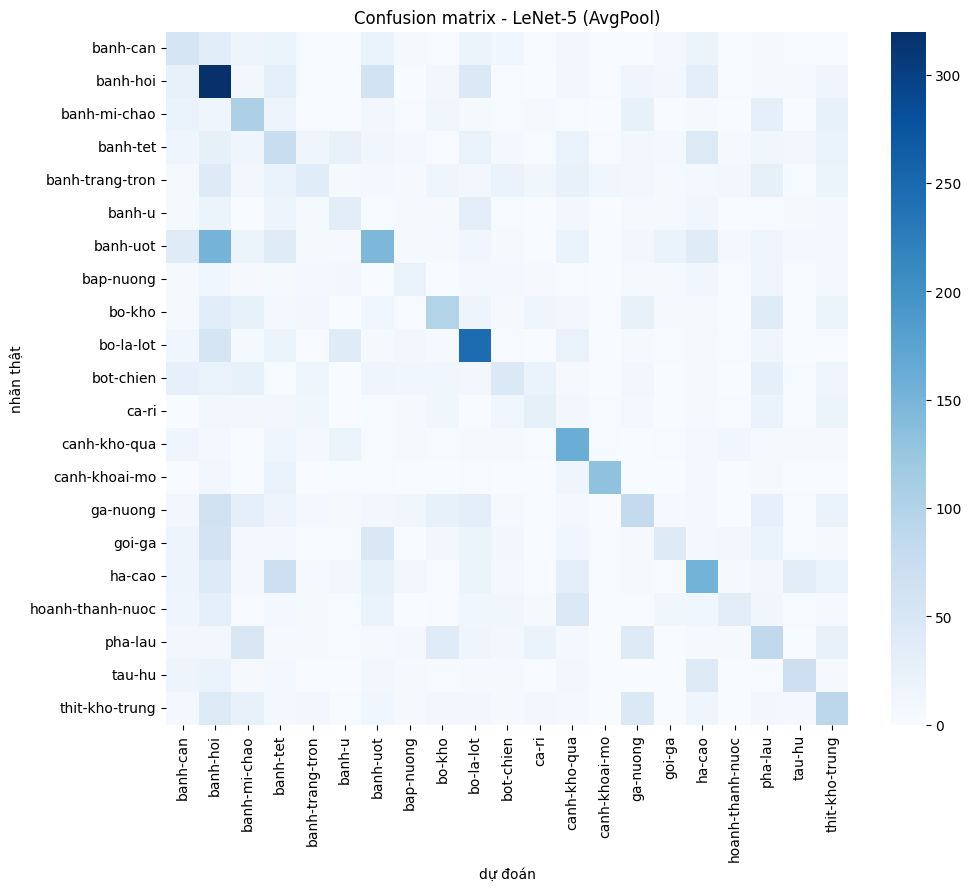

In [19]:
# Đường loss và kết quả trên tập test của bản AvgPool
plot_loss(hist_avg, "LeNet-5 (AvgPool)")
f1_avg = report(lenet_avg, test_dl, "LeNet-5 (AvgPool)", 64, sec_avg)

#### LeNet-5 với MaxPool2d

In [20]:
# Giữ nguyên mọi thứ, chỉ đổi pooling sang MaxPool
torch.manual_seed(SEED)
lenet_max = LeNet5(in_ch=3, img=64, num_classes=len(CLASSES),
                   pool="max").to(device)
optimizer = torch.optim.Adam(lenet_max.parameters(), lr=1e-3)
hist_max, sec_max = fit(lenet_max, optimizer, train_dl, val_dl, EPOCHS_LENET)

epoch  1  train 2.8116/0.1521   val 2.6578/0.1982  F1 0.1037  *
epoch  2  train 2.5993/0.2071   val 2.5286/0.2341  F1 0.1715  *
epoch  3  train 2.4914/0.2368   val 2.4601/0.2440  F1 0.1809  *
epoch  4  train 2.3996/0.2643   val 2.4303/0.2610  F1 0.2276  *
epoch  5  train 2.3081/0.2889   val 2.3070/0.2948  F1 0.2660  *
epoch  6  train 2.2498/0.3065   val 2.2683/0.2998  F1 0.2619
epoch  7  train 2.1869/0.3211   val 2.2825/0.3018  F1 0.2817  *
epoch  8  train 2.1480/0.3371   val 2.2248/0.2998  F1 0.2667
epoch  9  train 2.1163/0.3524   val 2.1987/0.3327  F1 0.3199  *
epoch 10  train 2.0661/0.3628   val 2.1414/0.3367  F1 0.3236  *
epoch 11  train 2.0446/0.3612   val 2.1456/0.3396  F1 0.3066
epoch 12  train 2.0065/0.3787   val 2.1568/0.3237  F1 0.3042
epoch 13  train 1.9831/0.3907   val 2.1169/0.3576  F1 0.3333  *
epoch 14  train 1.9575/0.3981   val 2.1449/0.3337  F1 0.3254
epoch 15  train 1.9413/0.4018   val 2.1430/0.3277  F1 0.3091
epoch 16  train 1.9137/0.4106   val 2.1091/0.3516  F1 0.32

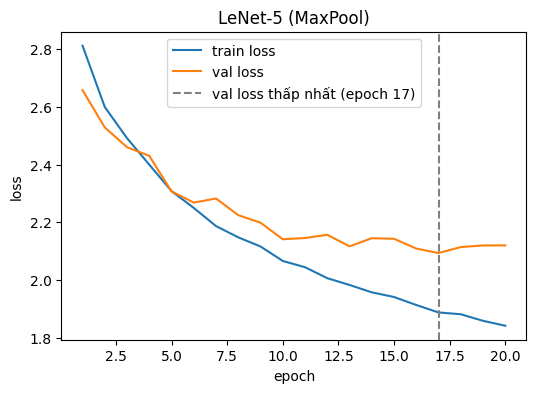

val loss thấp nhất ở epoch 17 rồi đi lên ở các epoch sau
độ đo          giá trị
accuracy        0.3255
precision       0.3200
recall          0.3158
macro-F1        0.3095

                  precision    recall  f1-score   support

        banh-can     0.2190    0.2199    0.2195       241
        banh-hoi     0.3638    0.4135    0.3870       607
    banh-mi-chao     0.3117    0.4325    0.3623       289
        banh-tet     0.2847    0.2308    0.2549       364
 banh-trang-tron     0.1897    0.1553    0.1708       309
          banh-u     0.3789    0.2045    0.2657       176
        banh-uot     0.3393    0.2714    0.3016       560
       bap-nuong     0.1818    0.1119    0.1385       143
          bo-kho     0.3557    0.2663    0.3046       338
       bo-la-lot     0.3789    0.6965    0.4908       458
       bot-chien     0.1828    0.1775    0.1801       276
           ca-ri     0.2083    0.2632    0.2326       171
    canh-kho-qua     0.5470    0.5414    0.5442       290
   canh-khoai-

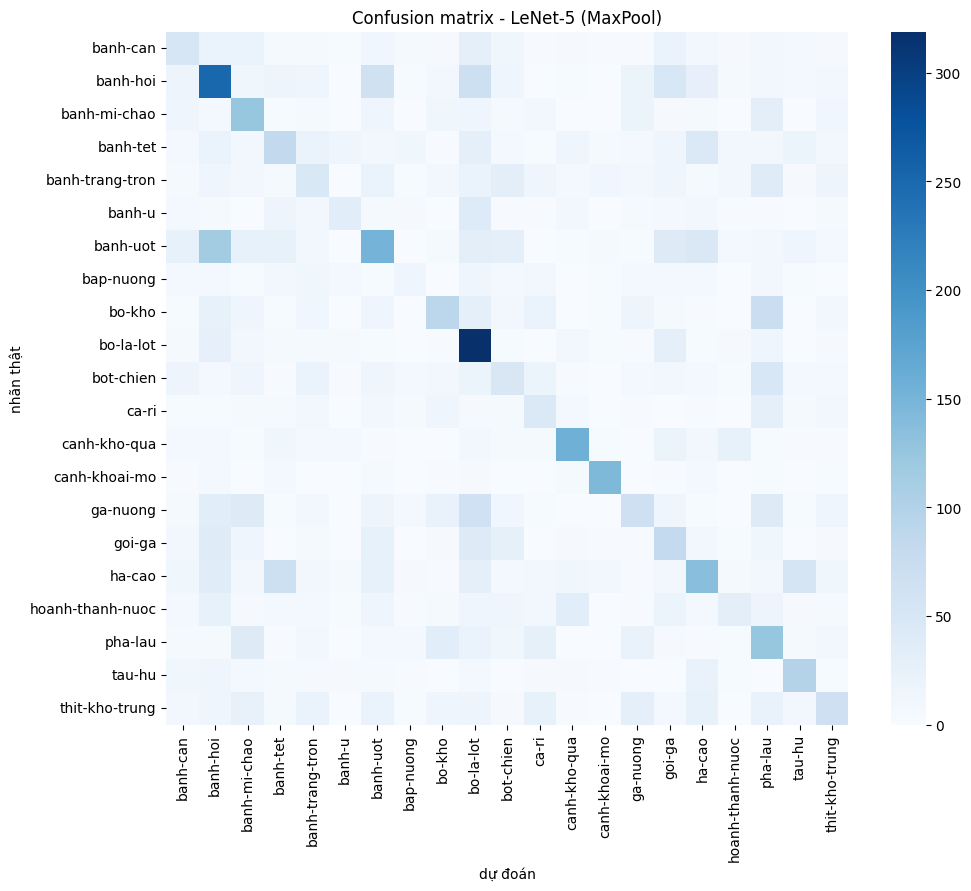

In [21]:
# Đường loss và kết quả trên tập test của bản MaxPool
plot_loss(hist_max, "LeNet-5 (MaxPool)")
f1_max = report(lenet_max, test_dl, "LeNet-5 (MaxPool)", 64, sec_max)

In [22]:
# So sánh macro-F1 của hai bản pooling
print(f"{'bản':<20}{'tham số':>12}{'macro-F1':>12}")
print(f"{'LeNet-5 AvgPool':<20}{n_params(lenet_avg):>12,}{f1_avg:>12.4f}")
print(f"{'LeNet-5 MaxPool':<20}{n_params(lenet_max):>12,}{f1_max:>12.4f}")
print(f"\nchênh lệch (Max - Avg): {f1_max - f1_avg:+.4f}")

# Nhận xét: pooling không có tham số, nên hai bản có cùng 339,421 tham số

bản                      tham số    macro-F1
LeNet-5 AvgPool          339,421      0.2905
LeNet-5 MaxPool          339,421      0.3095

chênh lệch (Max - Avg): +0.0190


**Nhận xét Bài 1**

- Hai bản có cùng 339,421 tham số vì pooling không có tham số, chạy cùng seed và cùng cấu hình huấn luyện.
- Macro-F1 trên test: AvgPool 0.2905, MaxPool 0.3095. Trong lần chạy này MaxPool cao hơn khoảng 0.02.

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

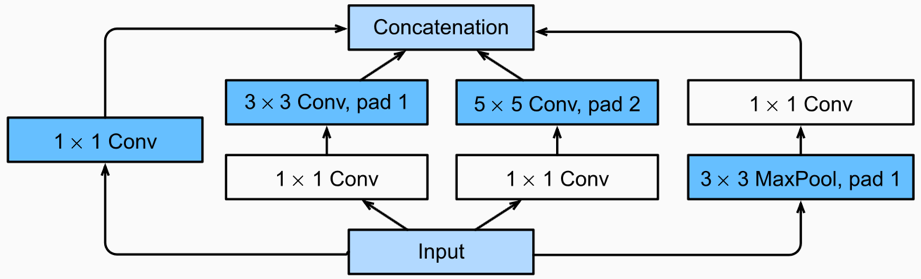

**GoogLeNet (Multi-branch Network)**

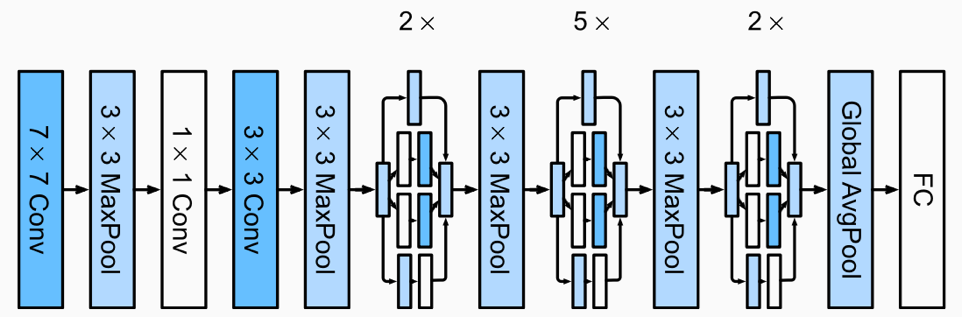

Bản rút gọn 4 Inception block cho ảnh 64x64, không có auxiliary classifier.
Các nhánh nối bằng `torch.cat(..., dim=1)`, trước lớp phân loại dùng
`nn.AdaptiveAvgPool2d(1)` thay cho `nn.Flatten()` (B.4).

| block | in | f1 | f3r | f3 | f5r | f5 | fp | channel ra = f1 + f3 + f5 + fp | H x W |
|---|---|---|---|---|---|---|---|---|---|
| inc1 | 32 | 16 | 16 | 24 | 4 | 8 | 8 | 16 + 24 + 8 + 8 = 56 | 32 x 32 |
| inc2 | 56 | 32 | 32 | 48 | 8 | 16 | 16 | 32 + 48 + 16 + 16 = 112 | 32 x 32 |
| inc3 | 112 | 64 | 48 | 96 | 16 | 32 | 32 | 64 + 96 + 32 + 32 = 224 | 16 x 16 |
| inc4 | 224 | 96 | 64 | 128 | 16 | 32 | 32 | 96 + 128 + 32 + 32 = 288 | 8 x 8 |

Channel vào của block sau bằng channel ra của block trước.

In [23]:
# Định nghĩa Inception block
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
            nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
            nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        # dim=1 là chiều channel
        return torch.cat([self.b1(x), self.b2(x),
                          self.b3(x), self.b4(x)], dim=1)

In [24]:
# Định nghĩa GoogLeNet rút gọn: stem, 4 Inception block, GAP, Linear
class GoogLeNet(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2))                                 # 64 -> 32
        self.inc1 = InceptionBlock(32, 16, 16, 24, 4, 8, 8)
        self.inc2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
        self.pool1 = nn.MaxPool2d(2, 2)                         # 32 -> 16
        self.inc3 = InceptionBlock(112, 64, 48, 96, 16, 32, 32)
        self.pool2 = nn.MaxPool2d(2, 2)                         # 16 -> 8
        self.inc4 = InceptionBlock(224, 96, 64, 128, 16, 32, 32)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(288, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.inc2(self.inc1(x)))
        x = self.pool2(self.inc3(x))
        x = self.inc4(x)
        return self.fc(self.gap(x).flatten(1))

In [25]:
# In shape sau mỗi block và đối chiếu số channel tính tay với code
gnet = GoogLeNet(num_classes=len(CLASSES))
x = torch.rand(1, 3, 64, 64)
tinh_tay = {"inc1": 56, "inc2": 112, "inc3": 224, "inc4": 288}

print(f"{'layer':<8}{'output shape':<22}{'tính tay':>10}{'tham số':>12}")
with torch.no_grad():
    x = gnet.stem(x)
    print(f"{'stem':<8}{str(tuple(x.shape)):<22}{'':>10}"
          f"{n_params(gnet.stem):>12,}")
    for name in ("inc1", "inc2", "pool1", "inc3", "pool2", "inc4"):
        x = getattr(gnet, name)(x)
        hand = tinh_tay.get(name, "")
        print(f"{name:<8}{str(tuple(x.shape)):<22}{hand:>10}"
              f"{n_params(getattr(gnet, name)):>12,}")
        if name in tinh_tay:
            assert x.shape[1] == tinh_tay[name]
    v = gnet.gap(x).flatten(1)
    print(f"{'gap':<8}{str(tuple(v.shape)):<22}{'':>10}{0:>12,}")
    print(f"{'fc':<8}{str(tuple(gnet.fc(v).shape)):<22}{'':>10}"
          f"{n_params(gnet.fc):>12,}")
print(f"{'TỔNG':<8}{'':<22}{'':>10}{n_params(gnet):>12,}")

layer   output shape            tính tay     tham số
stem    (1, 32, 32, 32)                          896
inc1    (1, 56, 32, 32)               56       5,740
inc2    (1, 112, 32, 32)             112      22,104
pool1   (1, 112, 16, 16)                           0
inc3    (1, 224, 16, 16)             224      72,480
pool2   (1, 224, 8, 8)                             0
inc4    (1, 288, 8, 8)               288     133,488
gap     (1, 288)                                   0
fc      (1, 21)                                6,069
TỔNG                                         240,777


In [26]:
# Huấn luyện GoogLeNet rút gọn, cùng dữ liệu 64x64 và Adam lr 1e-3 như Bài 1
EPOCHS_GNET = 20

torch.manual_seed(SEED)
gnet = GoogLeNet(num_classes=len(CLASSES)).to(device)
optimizer = torch.optim.Adam(gnet.parameters(), lr=1e-3)
hist_gnet, sec_gnet = fit(gnet, optimizer, train_dl, val_dl, EPOCHS_GNET)

epoch  1  train 2.9307/0.1129   val 2.8185/0.1444  F1 0.0483  *
epoch  2  train 2.7307/0.1618   val 2.6622/0.1853  F1 0.1226  *
epoch  3  train 2.5467/0.2148   val 2.4600/0.2331  F1 0.1750  *
epoch  4  train 2.3795/0.2639   val 2.3545/0.2799  F1 0.2346  *
epoch  5  train 2.2721/0.2923   val 2.3017/0.2958  F1 0.2537  *
epoch  6  train 2.1721/0.3259   val 2.1521/0.3536  F1 0.3069  *
epoch  7  train 2.1199/0.3414   val 2.1044/0.3496  F1 0.3085  *
epoch  8  train 2.0345/0.3639   val 1.9724/0.3994  F1 0.3654  *
epoch  9  train 1.9721/0.3929   val 1.9771/0.3775  F1 0.3462
epoch 10  train 1.9094/0.4022   val 1.9697/0.3964  F1 0.3704  *
epoch 11  train 1.8520/0.4168   val 1.9878/0.3934  F1 0.3622
epoch 12  train 1.8265/0.4299   val 1.8486/0.4124  F1 0.3765  *
epoch 13  train 1.7835/0.4431   val 1.8909/0.4193  F1 0.3973  *
epoch 14  train 1.7413/0.4517   val 1.7830/0.4382  F1 0.3961
epoch 15  train 1.7085/0.4593   val 1.8152/0.4422  F1 0.4110  *
epoch 16  train 1.6681/0.4775   val 1.7186/0.4422

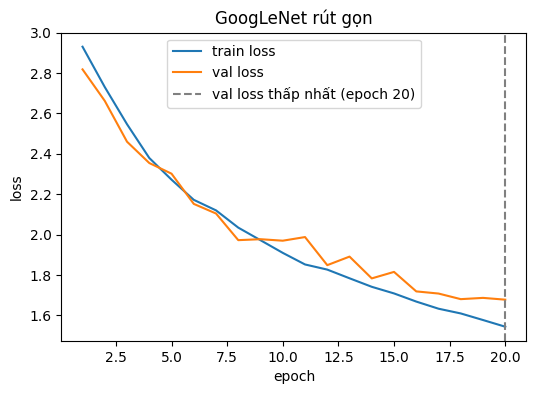

val loss vẫn giảm đến epoch cuối, chưa thấy đi lên
độ đo          giá trị
accuracy        0.4220
precision       0.4375
recall          0.4096
macro-F1        0.4084

                  precision    recall  f1-score   support

        banh-can     0.3333    0.2863    0.3080       241
        banh-hoi     0.5085    0.4926    0.5004       607
    banh-mi-chao     0.4556    0.5675    0.5054       289
        banh-tet     0.5380    0.4670    0.5000       364
 banh-trang-tron     0.2394    0.1100    0.1508       309
          banh-u     0.4513    0.2898    0.3529       176
        banh-uot     0.3631    0.4714    0.4103       560
       bap-nuong     0.2536    0.2448    0.2491       143
          bo-kho     0.6577    0.2899    0.4025       338
       bo-la-lot     0.6303    0.6441    0.6371       458
       bot-chien     0.2504    0.5543    0.3450       276
           ca-ri     0.3469    0.1988    0.2528       171
    canh-kho-qua     0.5181    0.6897    0.5917       290
   canh-khoai-mo    

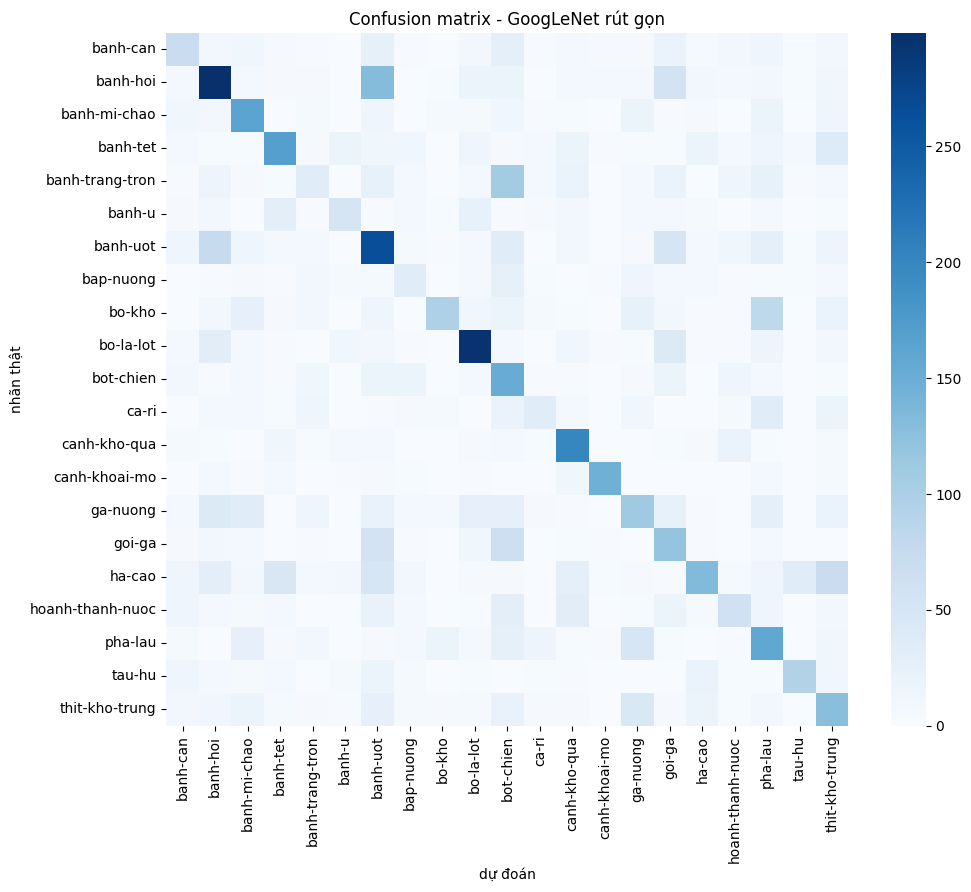

In [27]:
# Đường loss và kết quả trên tập test
plot_loss(hist_gnet, "GoogLeNet rút gọn")
f1_gnet = report(gnet, test_dl, "GoogLeNet rút gọn", 64, sec_gnet)

In [28]:
# So sánh với Bài 1: số tham số, thời gian mỗi epoch, macro-F1
print(f"{'mô hình':<22}{'tham số':>12}{'giây/epoch':>12}{'macro-F1':>10}")
for name in ("LeNet-5 (AvgPool)", "LeNet-5 (MaxPool)", "GoogLeNet rút gọn"):
    r = results[name]
    print(f"{name:<22}{r['params']:>12,}{r['sec']:>12.1f}{r['f1']:>10.4f}")

mô hình                    tham số  giây/epoch  macro-F1
LeNet-5 (AvgPool)          339,421         4.1    0.2905
LeNet-5 (MaxPool)          339,421         4.0    0.3095
GoogLeNet rút gọn          240,777         4.0    0.4084


**Nhận xét Bài 2**

- Số channel ra của 4 block là 56, 112, 224, 288, khớp giữa tính tay và code. inc1 có 5,740 tham số (khác 4,376 ở B.4) vì nhận 32 channel từ stem thay vì 1.
- So với Bài 1: GoogLeNet rút gọn có ít tham số hơn (240,777 so với 339,421), thời gian mỗi epoch gần như bằng nhau (4.0 so với 4.0-4.1 giây, tính cả bước đánh giá val) và macro-F1 cao hơn (0.4084 so với 0.3095 của bản LeNet tốt nhất).

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

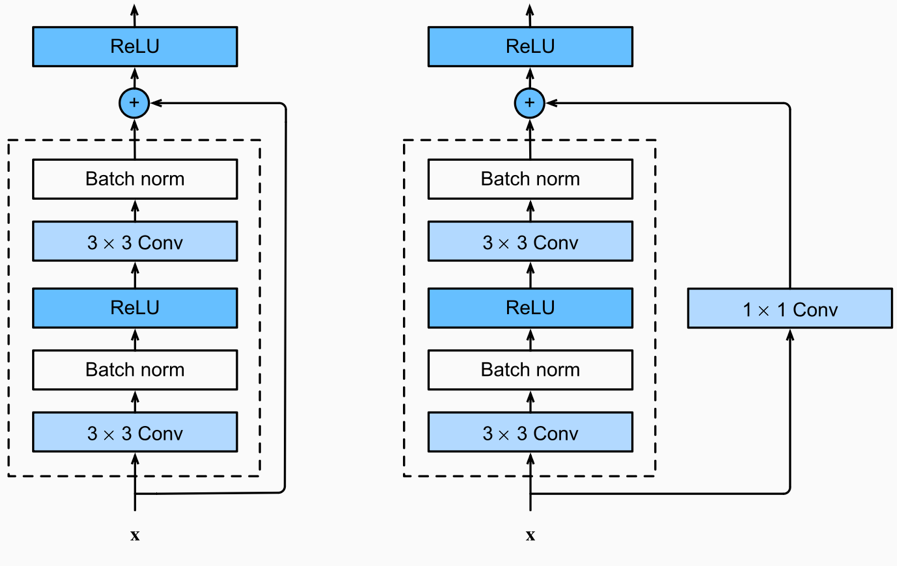

**ResNet**

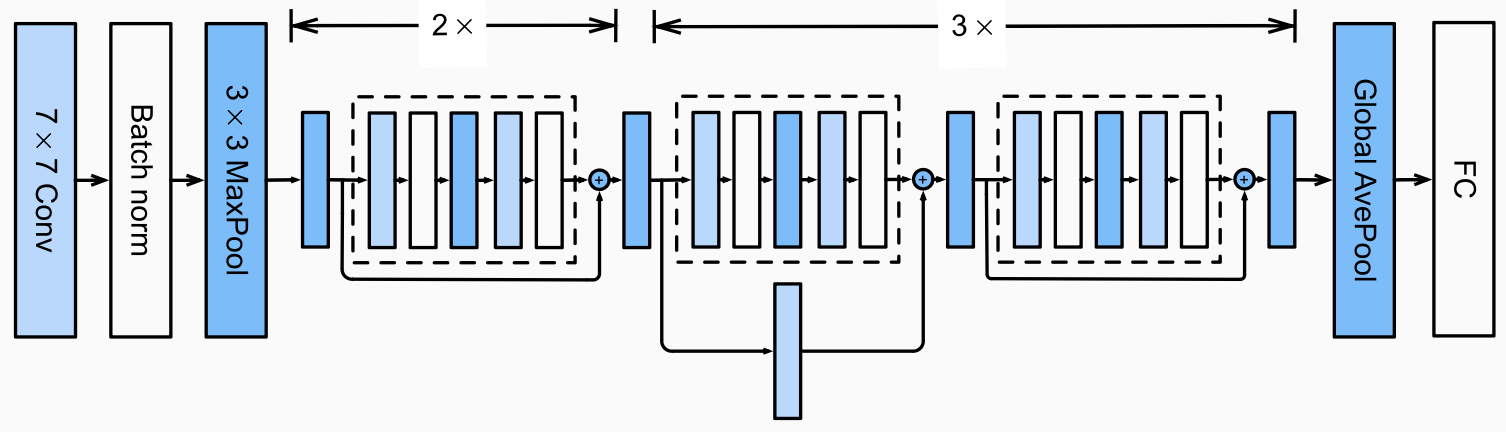

ResNet-18 đầy đủ `[2, 2, 2, 2]` BasicBlock, huấn luyện từ đầu (không dùng trọng
số pretrained), ảnh 96x96 vì ảnh 64x64 chỉ còn 2x2 ở layer4 (B.5 Bước 4). Chạy
hai lần: có và không có augmentation.

In [29]:
# Định nghĩa BasicBlock
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1,
                               bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:      # cần projection
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x)            # cộng trước
        return torch.relu(out)                  # ReLU sau

In [30]:
# Định nghĩa ResNet-18 theo bốn stage
class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        # Block đầu chịu trách nhiệm đổi channel và giảm chiều
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride),
                             BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))

In [31]:
# Bảng shape và tham số qua từng stage, với ảnh vào 96x96
IMG_RESNET = 96

r18 = ResNet18(num_classes=len(CLASSES))
x = torch.rand(1, 3, IMG_RESNET, IMG_RESNET)

print(f"{'stage':<12}{'output shape':<20}{'tham số':>12}")
with torch.no_grad():
    x = r18.stem(x)
    print(f"{'stem':<12}{str(tuple(x.shape)):<20}{n_params(r18.stem):>12,}")
    for name in ("layer1", "layer2", "layer3", "layer4"):
        layer = getattr(r18, name)
        x = layer(x)
        print(f"{name:<12}{str(tuple(x.shape)):<20}{n_params(layer):>12,}")
    v = r18.pool(x).flatten(1)
    print(f"{'avgpool':<12}{str(tuple(v.shape)):<20}{0:>12,}")
    print(f"{'fc':<12}{str(tuple(r18.fc(v).shape)):<20}"
          f"{n_params(r18.fc):>12,}")
print(f"{'TỔNG':<12}{'':<20}{n_params(r18):>12,}")

assert n_params(r18) == 11_187_285
assert tuple(x.shape) == (1, 512, 3, 3)

stage       output shape             tham số
stem        (1, 64, 24, 24)            9,536
layer1      (1, 64, 24, 24)          147,968
layer2      (1, 128, 12, 12)         525,568
layer3      (1, 256, 6, 6)         2,099,712
layer4      (1, 512, 3, 3)         8,393,728
avgpool     (1, 512)                       0
fc          (1, 21)                   10,773
TỔNG                              11,187,285


In [32]:
# Đối chiếu số tham số với bản resnet18 của torchvision
tv = tv_resnet18(weights=None)
tv.fc = nn.Linear(512, len(CLASSES))
print("torchvision resnet18, fc 21 lớp:", f"{n_params(tv):,}")
print("bản tự cài                     :", f"{n_params(r18):,}")
assert n_params(tv) == n_params(r18)

torchvision resnet18, fc 21 lớp: 11,187,285
bản tự cài                     : 11,187,285


#### Lần 1: có augmentation

In [33]:
# DataLoader 96x96 có augment, huấn luyện ResNet-18 từ đầu với Adam lr 1e-3
EPOCHS_RESNET = 20

train_dl96, val_dl96, test_dl96 = build_loaders(IMG_RESNET, augment=True)

torch.manual_seed(SEED)
r18_aug = ResNet18(num_classes=len(CLASSES)).to(device)
optimizer = torch.optim.Adam(r18_aug.parameters(), lr=1e-3)
hist_aug, sec_aug = fit(r18_aug, optimizer, train_dl96, val_dl96,
                        EPOCHS_RESNET)

epoch  1  train 2.7063/0.1862   val 2.5699/0.2341  F1 0.1705  *
epoch  2  train 2.4514/0.2471   val 2.3362/0.2888  F1 0.2543  *
epoch  3  train 2.3150/0.2850   val 2.2894/0.2819  F1 0.2359
epoch  4  train 2.1790/0.3278   val 2.3128/0.3018  F1 0.2870  *
epoch  5  train 2.0560/0.3632   val 2.6530/0.2699  F1 0.2388
epoch  6  train 1.9643/0.3894   val 1.9981/0.3725  F1 0.3414  *
epoch  7  train 1.8724/0.4189   val 1.8807/0.4173  F1 0.3779  *
epoch  8  train 1.7841/0.4433   val 1.7849/0.4442  F1 0.3874  *
epoch  9  train 1.6852/0.4690   val 1.7188/0.4582  F1 0.4398  *
epoch 10  train 1.6237/0.4847   val 1.7939/0.4641  F1 0.4369
epoch 11  train 1.5555/0.5095   val 1.7351/0.4592  F1 0.4282
epoch 12  train 1.4805/0.5304   val 1.7053/0.4532  F1 0.4436  *
epoch 13  train 1.4294/0.5466   val 1.5670/0.4861  F1 0.4766  *
epoch 14  train 1.3513/0.5670   val 1.5912/0.5010  F1 0.4870  *
epoch 15  train 1.3082/0.5858   val 1.5709/0.4980  F1 0.4930  *
epoch 16  train 1.2268/0.6034   val 1.6709/0.4920  F

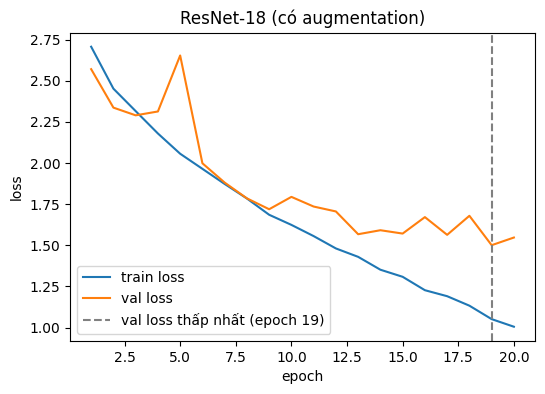

val loss thấp nhất ở epoch 19 rồi đi lên ở các epoch sau
độ đo          giá trị
accuracy        0.4945
precision       0.5074
recall          0.4865
macro-F1        0.4802

                  precision    recall  f1-score   support

        banh-can     0.2759    0.6183    0.3816       241
        banh-hoi     0.5163    0.6507    0.5758       607
    banh-mi-chao     0.5514    0.6125    0.5803       289
        banh-tet     0.6957    0.5275    0.6000       364
 banh-trang-tron     0.4889    0.2136    0.2973       309
          banh-u     0.4027    0.5057    0.4484       176
        banh-uot     0.4846    0.3661    0.4171       560
       bap-nuong     0.4507    0.2238    0.2991       143
          bo-kho     0.5729    0.3373    0.4246       338
       bo-la-lot     0.6205    0.6463    0.6332       458
       bot-chien     0.3621    0.4710    0.4094       276
           ca-ri     0.3377    0.3041    0.3200       171
    canh-kho-qua     0.7435    0.6897    0.7156       290
   canh-khoai-

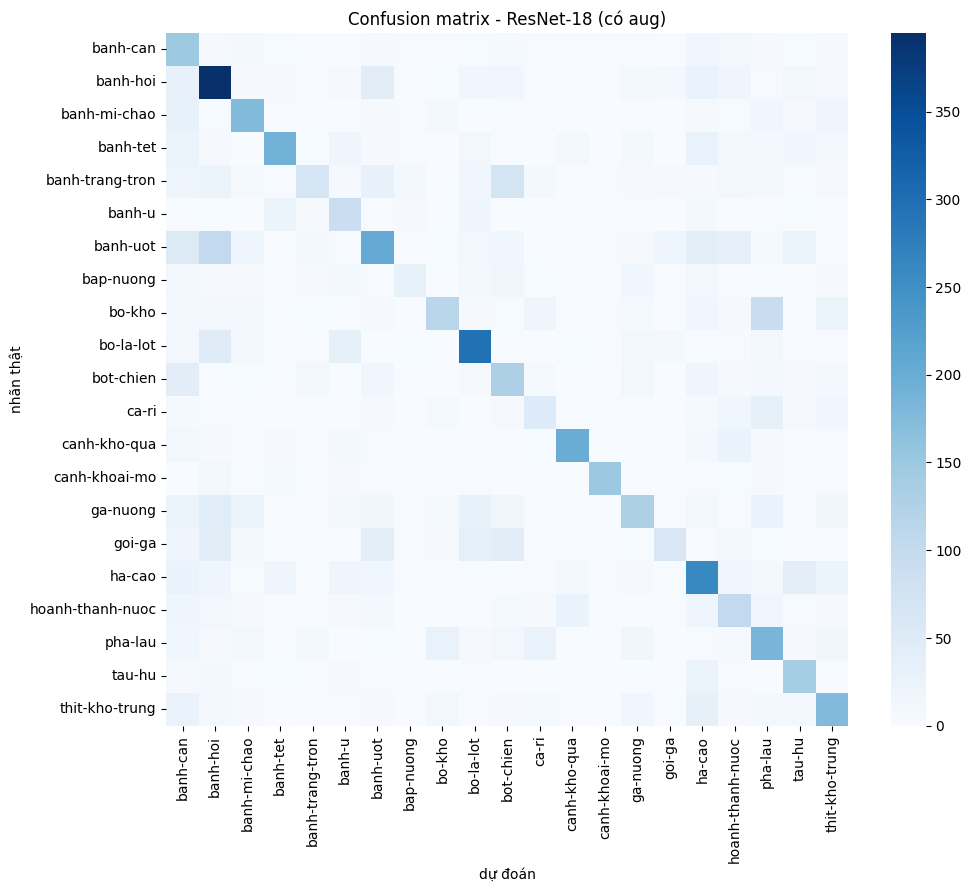

In [34]:
# Đường loss và kết quả trên tập test, có augmentation
plot_loss(hist_aug, "ResNet-18 (có augmentation)")
f1_aug = report(r18_aug, test_dl96, "ResNet-18 (có aug)", IMG_RESNET,
                sec_aug)

#### Lần 2: không có augmentation

In [35]:
# Train dùng cùng transform với val/test, các cấu hình khác giữ nguyên
train_dl96_na, val_dl96_na, test_dl96_na = build_loaders(IMG_RESNET,
                                                         augment=False)

torch.manual_seed(SEED)
r18_noaug = ResNet18(num_classes=len(CLASSES)).to(device)
optimizer = torch.optim.Adam(r18_noaug.parameters(), lr=1e-3)
hist_noaug, sec_noaug = fit(r18_noaug, optimizer, train_dl96_na,
                            val_dl96_na, EPOCHS_RESNET)

epoch  1  train 2.6419/0.2024   val 2.4451/0.2570  F1 0.1854  *
epoch  2  train 2.3553/0.2769   val 2.2878/0.3048  F1 0.2772  *
epoch  3  train 2.1657/0.3305   val 2.2925/0.3088  F1 0.2687
epoch  4  train 1.9828/0.3789   val 2.2428/0.3357  F1 0.3161  *
epoch  5  train 1.8068/0.4352   val 2.1921/0.3765  F1 0.3532  *
epoch  6  train 1.6195/0.4889   val 1.9954/0.3944  F1 0.3817  *
epoch  7  train 1.4090/0.5544   val 1.8249/0.4382  F1 0.4208  *
epoch  8  train 1.1679/0.6212   val 1.8704/0.4602  F1 0.4315  *
epoch  9  train 0.8692/0.7162   val 1.9290/0.4512  F1 0.4234
epoch 10  train 0.5894/0.8106   val 2.2022/0.4821  F1 0.4787  *
epoch 11  train 0.3697/0.8803   val 2.3200/0.4900  F1 0.4694
epoch 12  train 0.2412/0.9221   val 2.4763/0.4791  F1 0.4782
epoch 13  train 0.1921/0.9383   val 2.5858/0.4731  F1 0.4736
epoch 14  train 0.1561/0.9502   val 2.7410/0.4542  F1 0.4449
epoch 15  train 0.1187/0.9625   val 3.1129/0.4452  F1 0.4495
epoch 16  train 0.0791/0.9742   val 2.9454/0.4582  F1 0.4558


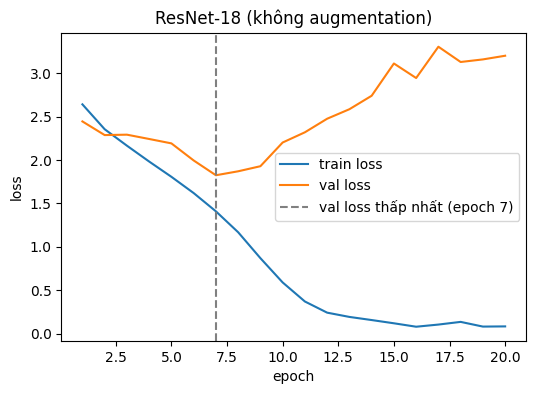

val loss thấp nhất ở epoch 7 rồi đi lên ở các epoch sau
độ đo          giá trị
accuracy        0.3928
precision       0.4007
recall          0.3746
macro-F1        0.3667

                  precision    recall  f1-score   support

        banh-can     0.3942    0.1701    0.2377       241
        banh-hoi     0.3923    0.6244    0.4819       607
    banh-mi-chao     0.5255    0.2491    0.3380       289
        banh-tet     0.4821    0.3709    0.4193       364
 banh-trang-tron     0.3738    0.1294    0.1923       309
          banh-u     0.3038    0.2727    0.2874       176
        banh-uot     0.3393    0.3732    0.3554       560
       bap-nuong     0.2613    0.2028    0.2283       143
          bo-kho     0.5297    0.3432    0.4165       338
       bo-la-lot     0.5507    0.7227    0.6251       458
       bot-chien     0.3726    0.2862    0.3238       276
           ca-ri     0.2537    0.3041    0.2766       171
    canh-kho-qua     0.4026    0.5414    0.4618       290
   canh-khoai-m

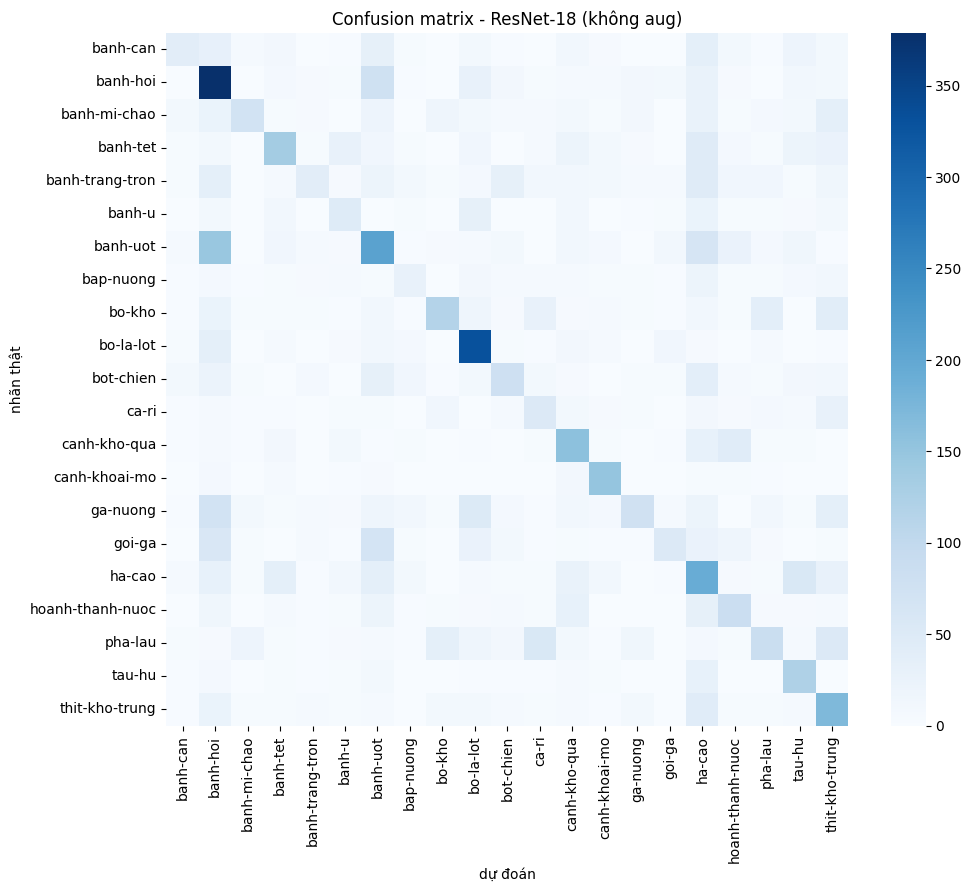

In [36]:
# Đường loss và kết quả trên tập test, không có augmentation
plot_loss(hist_noaug, "ResNet-18 (không augmentation)")
f1_noaug = report(r18_noaug, test_dl96_na, "ResNet-18 (không aug)",
                  IMG_RESNET, sec_noaug)

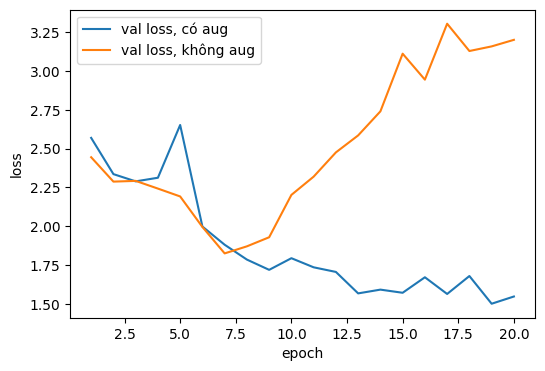

macro-F1 có aug    : 0.4802
macro-F1 không aug : 0.3667
chênh lệch         : +0.1135


In [37]:
# Đặt hai đường val loss cạnh nhau và tính chênh lệch macro-F1
ep, _, va_aug = zip(*hist_aug)
_, _, va_noaug = zip(*hist_noaug)
plt.figure(figsize=(6, 4))
plt.plot(ep, va_aug, label="val loss, có aug")
plt.plot(ep, va_noaug, label="val loss, không aug")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

print(f"macro-F1 có aug    : {f1_aug:.4f}")
print(f"macro-F1 không aug : {f1_noaug:.4f}")
print(f"chênh lệch         : {f1_aug - f1_noaug:+.4f}")

**Nhận xét Bài 3**

- Không augmentation: val loss thấp nhất ở epoch 7 (1.82) rồi đi lên trong khi train loss tiếp tục giảm, train accuracy đạt 97.2% ở epoch 20. Hai đường tách nhau từ epoch 7. Checkpoint đem đi test (theo val macro-F1) là epoch 10.
- Có augmentation: khoảng cách giữa train loss và val loss bắt đầu nới rộng từ khoảng epoch 10, nhưng val loss vẫn có xu hướng giảm tới epoch 19 (1.50) và chỉ tăng nhẹ ở epoch 20, nên trong 20 epoch chưa thấy val loss đi lên rõ. Checkpoint đem đi test là epoch 20.
- Macro-F1 trên test: có augmentation 0.4802, không augmentation 0.3667, chênh lệch 0.1135.

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

Dùng `microsoft/resnet-50` từ HuggingFace làm backbone, thay classifier 1000 lớp
bằng `nn.Linear(2048, 21)`. Ảnh resize 224x224, chuẩn hoá bằng mean/std của
ImageNet. Chạy hai chế độ (B.6):

- feature extraction: đóng băng backbone, Adam lr 1e-3
- fine-tuning: cập nhật toàn mạng, Adam lr 1e-4

Ô đầu tiên tải khoảng 100 MB trọng số. Nên chạy phần này trên GPU.

In [38]:
# Kiểm tra mean/std đi kèm model trùng với MEAN, STD đang dùng
from transformers import AutoImageProcessor, ResNetForImageClassification

proc = AutoImageProcessor.from_pretrained("microsoft/resnet-50")
print("mean:", proc.image_mean)
print("std :", proc.image_std)
assert [round(v, 3) for v in proc.image_mean] == MEAN
assert [round(v, 3) for v in proc.image_std] == STD

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

mean: (0.485, 0.456, 0.406)
std : (0.229, 0.224, 0.225)


In [39]:
# Định nghĩa model: backbone pretrained + classifier mới 21 lớp
class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained(
            "microsoft/resnet-50")
        self.resnet = base.resnet
        self.classifier = nn.Linear(2048, num_classes, bias=True)

        if freeze_backbone:     # hai dòng này tạo ra feature extraction
            for p in self.resnet.parameters():
                p.requires_grad = False

    def forward(self, images):
        features = self.resnet(images).pooler_output    # [B, 2048, 1, 1]
        features = features.squeeze(-1).squeeze(-1)    # [B, 2048]
        return self.classifier(features)                # [B, 21]

In [40]:
# Theo dõi shape từ ảnh vào đến logits và số tham số được cập nhật
IMG_TL = 224

fe = PretrainedResnet(len(CLASSES), freeze_backbone=True)
ft = PretrainedResnet(len(CLASSES), freeze_backbone=False)

x = torch.rand(2, 3, IMG_TL, IMG_TL)
fe.eval()
with torch.no_grad():
    feats = fe.resnet(x).pooler_output
    show("ảnh vào", x)
    show("pooler_output", feats)
    show("logits", fe(x))
print()

print(f"{'chế độ':<22}{'tổng':>14}{'được cập nhật':>16}{'lr':>8}")
print(f"{'feature extraction':<22}{n_params(fe):>14,}"
      f"{n_params(fe, True):>16,}{'1e-3':>8}")
print(f"{'fine-tuning':<22}{n_params(ft):>14,}"
      f"{n_params(ft, True):>16,}{'1e-4':>8}")

assert n_params(fe) == 23_551_061
assert n_params(fe, trainable_only=True) == 43_029      # chỉ classifier
assert n_params(ft, trainable_only=True) == 23_551_061

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

ảnh vào                      (2, 3, 224, 224)
pooler_output                (2, 2048, 1, 1)
logits                       (2, 21)

chế độ                          tổng   được cập nhật      lr
feature extraction        23,551,061          43,029    1e-3
fine-tuning               23,551,061      23,551,061    1e-4


#### Feature extraction

In [41]:
# DataLoader 224x224, huấn luyện chỉ classifier với Adam lr 1e-3
EPOCHS_TL = 10

train_dl224, val_dl224, test_dl224 = build_loaders(IMG_TL, augment=True)

torch.manual_seed(SEED)
fe = PretrainedResnet(len(CLASSES), freeze_backbone=True).to(device)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, fe.parameters()), lr=1e-3)
n_opt = sum(p.numel() for g in optimizer.param_groups for p in g["params"])
print("tham số nằm trong optimizer:", f"{n_opt:,}")
assert n_opt == 43_029

hist_fe, sec_fe = fit(fe, optimizer, train_dl224, val_dl224, EPOCHS_TL)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

tham số nằm trong optimizer: 43,029
epoch  1  train 2.4854/0.3121   val 2.2539/0.4084  F1 0.4009  *
epoch  2  train 1.9055/0.5071   val 1.9459/0.4791  F1 0.4847  *
epoch  3  train 1.6570/0.5528   val 1.7255/0.5388  F1 0.5391  *
epoch  4  train 1.5132/0.5863   val 1.6350/0.5428  F1 0.5518  *
epoch  5  train 1.4080/0.6046   val 1.5542/0.5717  F1 0.5797  *
epoch  6  train 1.3196/0.6364   val 1.4888/0.5857  F1 0.5857  *
epoch  7  train 1.2611/0.6481   val 1.4570/0.5916  F1 0.5929  *
epoch  8  train 1.2099/0.6563   val 1.3925/0.6165  F1 0.6256  *
epoch  9  train 1.1782/0.6654   val 1.3765/0.6066  F1 0.6146
epoch 10  train 1.1391/0.6736   val 1.3341/0.6205  F1 0.6250

9.8 giây/epoch, best val macro-F1 0.6256


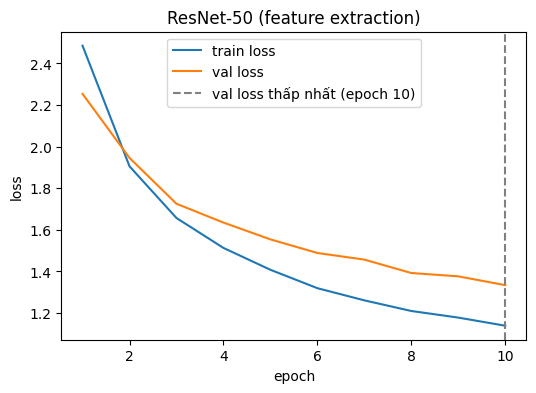

val loss vẫn giảm đến epoch cuối, chưa thấy đi lên
độ đo          giá trị
accuracy        0.5694
precision       0.6071
recall          0.5750
macro-F1        0.5726

                  precision    recall  f1-score   support

        banh-can     0.4941    0.6971    0.5783       241
        banh-hoi     0.6463    0.4366    0.5211       607
    banh-mi-chao     0.5231    0.7059    0.6009       289
        banh-tet     0.9357    0.4396    0.5981       364
 banh-trang-tron     0.7448    0.4628    0.5709       309
          banh-u     0.6474    0.6989    0.6721       176
        banh-uot     0.5218    0.3839    0.4424       560
       bap-nuong     0.8818    0.6783    0.7668       143
          bo-kho     0.3973    0.6864    0.5033       338
       bo-la-lot     0.4978    0.7576    0.6009       458
       bot-chien     0.4646    0.5471    0.5025       276
           ca-ri     0.2737    0.1520    0.1955       171
    canh-kho-qua     0.6860    0.7759    0.7282       290
   canh-khoai-mo    

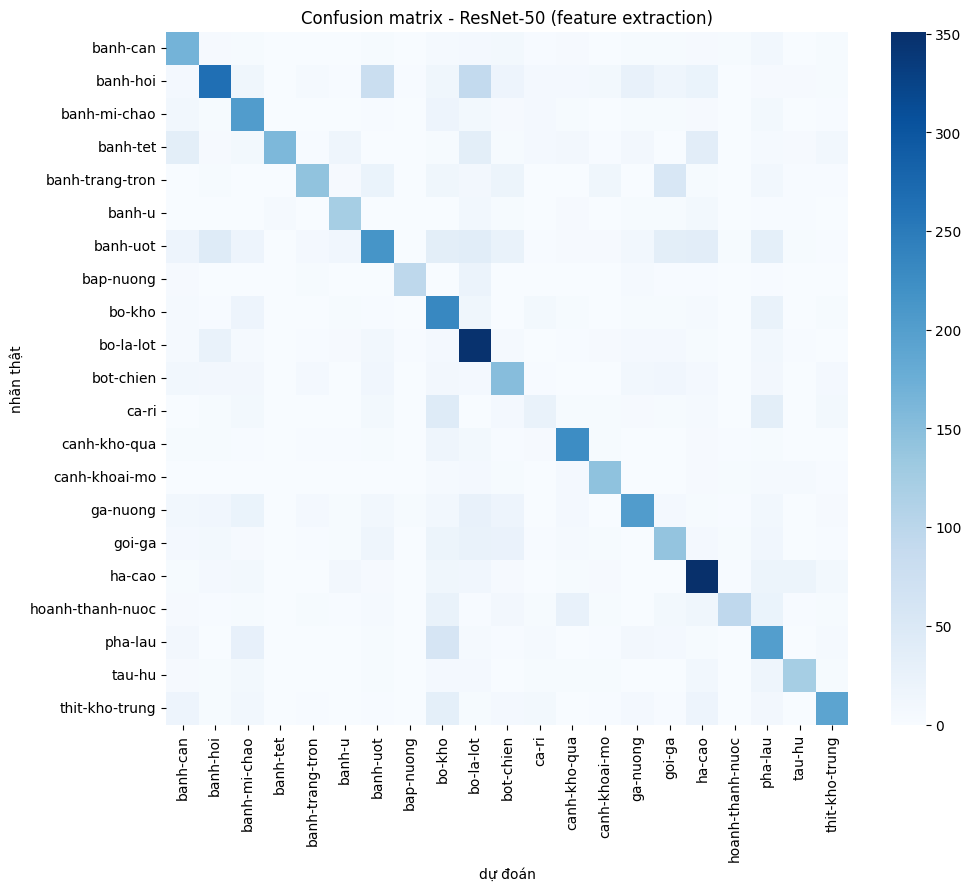

In [42]:
# Đường loss và kết quả trên tập test, feature extraction
plot_loss(hist_fe, "ResNet-50 (feature extraction)")
f1_fe = report(fe, test_dl224, "ResNet-50 (feature extraction)", IMG_TL,
               sec_fe)

#### Fine-tuning

In [43]:
# Cập nhật toàn mạng với Adam lr 1e-4
torch.manual_seed(SEED)
ft = PretrainedResnet(len(CLASSES), freeze_backbone=False).to(device)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, ft.parameters()), lr=1e-4)
hist_ft, sec_ft = fit(ft, optimizer, train_dl224, val_dl224, EPOCHS_TL)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

epoch  1  train 2.7535/0.1869   val 2.3158/0.3825  F1 0.2729  *
epoch  2  train 1.6875/0.5431   val 1.1221/0.6942  F1 0.6708  *
epoch  3  train 1.0151/0.7037   val 0.7578/0.7689  F1 0.7553  *
epoch  4  train 0.7453/0.7722   val 0.6099/0.8008  F1 0.7913  *
epoch  5  train 0.5859/0.8177   val 0.5205/0.8237  F1 0.8211  *
epoch  6  train 0.4859/0.8506   val 0.4900/0.8317  F1 0.8242  *
epoch  7  train 0.4081/0.8737   val 0.4847/0.8406  F1 0.8376  *
epoch  8  train 0.3490/0.8906   val 0.4415/0.8566  F1 0.8554  *
epoch  9  train 0.3061/0.9072   val 0.4297/0.8586  F1 0.8555  *
epoch 10  train 0.2747/0.9138   val 0.4157/0.8715  F1 0.8732  *

9.9 giây/epoch, best val macro-F1 0.8732


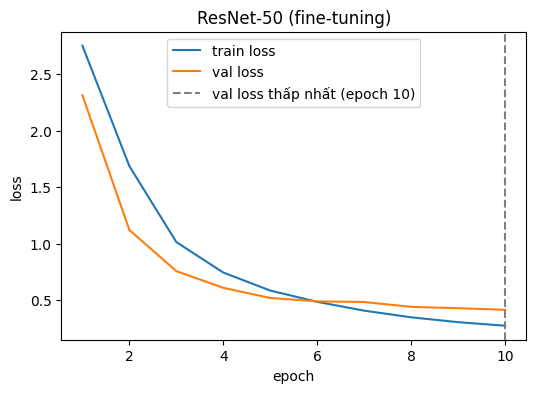

val loss vẫn giảm đến epoch cuối, chưa thấy đi lên
độ đo          giá trị
accuracy        0.8385
precision       0.8434
recall          0.8389
macro-F1        0.8392

                  precision    recall  f1-score   support

        banh-can     0.8199    0.9253    0.8694       241
        banh-hoi     0.7793    0.9077    0.8387       607
    banh-mi-chao     0.8931    0.8962    0.8946       289
        banh-tet     0.9801    0.8132    0.8889       364
 banh-trang-tron     0.9294    0.7670    0.8404       309
          banh-u     0.8205    0.9091    0.8625       176
        banh-uot     0.7815    0.7536    0.7673       560
       bap-nuong     0.9650    0.9650    0.9650       143
          bo-kho     0.7799    0.7337    0.7561       338
       bo-la-lot     0.8822    0.9323    0.9066       458
       bot-chien     0.7852    0.8478    0.8153       276
           ca-ri     0.5742    0.5205    0.5460       171
    canh-kho-qua     0.9324    0.9517    0.9420       290
   canh-khoai-mo    

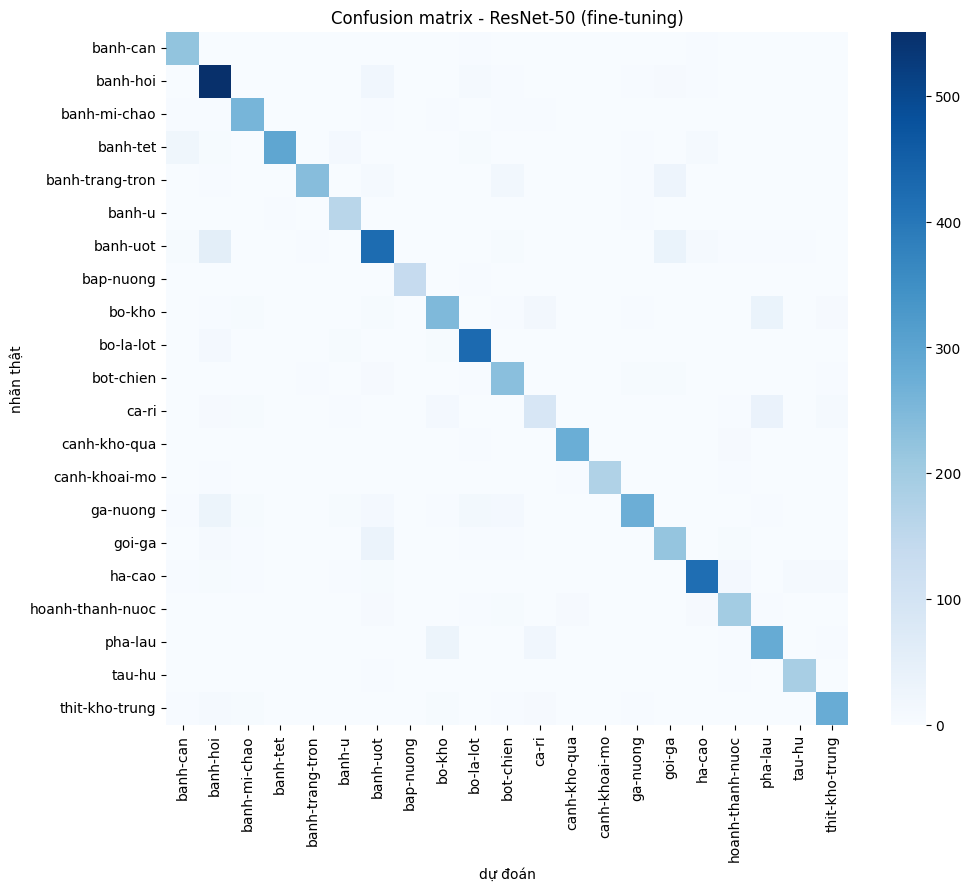

In [44]:
# Đường loss và kết quả trên tập test, fine-tuning
plot_loss(hist_ft, "ResNet-50 (fine-tuning)")
f1_ft = report(ft, test_dl224, "ResNet-50 (fine-tuning)", IMG_TL, sec_ft)

**Nhận xét Bài 4**

- Macro-F1 trên test: fine-tuning 0.8392, feature extraction 0.5726, ResNet-18 huấn luyện từ đầu ở Bài 3 (bản có augmentation) 0.4802. Fine-tuning cao hơn huấn luyện từ đầu khoảng 0.36.
- Giải thích: backbone ResNet-50 đã được huấn luyện trước trên ImageNet nên có sẵn đặc trưng ảnh tổng quát, còn ResNet-18 ở Bài 3 phải học 11 triệu tham số từ khoảng 9 nghìn ảnh. Feature extraction chỉ học classifier (43,029 tham số) vẫn cao hơn ResNet-18 từ đầu; fine-tuning cho cả backbone thích nghi với ảnh món ăn nên cao nhất. Lưu ý phép so sánh này còn khác nhau về kích thước ảnh (224 so với 96) và độ sâu mạng, nên không tách riêng được phần đóng góp của pretrain.
- Feature extraction dừng ở epoch 10 khi val loss vẫn đang giảm, nên kết quả này có thể còn tăng nếu huấn luyện thêm.

### Bảng tổng hợp kết quả

In [45]:
# Bảng so sánh các mô hình, số liệu lấy từ các lần chạy ở trên
print(f"{'mô hình':<32}{'resize':>9}{'tham số':>13}{'giây/epoch':>12}"
      f"{'acc':>8}{'prec':>8}{'rec':>8}{'F1':>8}")
for name, r in results.items():
    size = f"{r['img']}x{r['img']}"
    print(f"{name:<32}{size:>9}{r['params']:>13,}{r['sec']:>12.1f}"
          f"{r['acc']:>8.4f}{r['prec']:>8.4f}{r['rec']:>8.4f}"
          f"{r['f1']:>8.4f}")

mô hình                            resize      tham số  giây/epoch     acc    prec     rec      F1
LeNet-5 (AvgPool)                   64x64      339,421         4.1  0.3086  0.3061  0.2916  0.2905
LeNet-5 (MaxPool)                   64x64      339,421         4.0  0.3255  0.3200  0.3158  0.3095
GoogLeNet rút gọn                   64x64      240,777         4.0  0.4220  0.4375  0.4096  0.4084
ResNet-18 (có aug)                  96x96   11,187,285         4.8  0.4945  0.5074  0.4865  0.4802
ResNet-18 (không aug)               96x96   11,187,285         3.3  0.3928  0.4007  0.3746  0.3667
ResNet-50 (feature extraction)    224x224   23,551,061         9.8  0.5694  0.6071  0.5750  0.5726
ResNet-50 (fine-tuning)           224x224   23,551,061         9.9  0.8385  0.8434  0.8389  0.8392
